In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('returns_sustainability_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (5000, 27)


,order_id,product_id,user_id,order_date,product_category,product_price,order_quantity,discount_applied,shipping_method,payment_method,...,return_cost,profit_loss,co2_emissions,packaging_waste,co2_saved,waste_avoided,returned,order_month,order_year,discount_bin
0,ORD00000,PROD0169,USER0195,2022-01-14,Clothing,1720.71,2,30.46,Next-Day,Wallet,...,0,2393.163468,2.0,0.4,2.0,0.4,False,2022-01,2022,"(25.02, 37.38]"
1,ORD00001,PROD0318,USER1469,2022-01-03,Toys,744.06,5,29.62,Next-Day,Wallet,...,200,2418.347140,2.0,1.0,0.0,0.0,True,2022-01,2022,"(25.02, 37.38]"
2,ORD00002,PROD0427,USER1812,2025-03-16,Clothing,983.68,5,47.80,Express,Wallet,...,0,2567.404800,1.5,1.0,1.5,1.0,False,2025-03,2025,"(37.38, 50.0]"
3,ORD00003,PROD0323,USER1274,2024-11-06,Books,1855.65,2,2.90,Express,COD,...,0,3603.672300,1.5,0.4,1.5,0.4,False,2024-11,2024,"(-0.001, 12.828]"
4,ORD00004,PROD0325,USER0551,2023-06-07,Home Appliances,1770.97,5,44.42,Express,COD,...,200,4721.525630,1.5,1.0,0.0,0.0,True,2023-06,2023,"(37.38, 50.0]"


In [3]:
print(df.columns.tolist())

['order_id', 'product_id', 'user_id', 'order_date', 'product_category', 'product_price', 'order_quantity', 'discount_applied', 'shipping_method', 'payment_method', 'user_age', 'user_gender', 'user_location', 'return_status', 'return_reason', 'days_to_return', 'order_value', 'return_cost', 'profit_loss', 'co2_emissions', 'packaging_waste', 'co2_saved', 'waste_avoided', 'returned', 'order_month', 'order_year', 'discount_bin']


In [4]:
print(df.dtypes)

order_id                str
product_id              str
user_id                 str
order_date              str
product_category        str
product_price       float64
order_quantity        int64
discount_applied    float64
shipping_method         str
payment_method          str
user_age              int64
user_gender             str
user_location           str
return_status           str
return_reason           str
days_to_return        int64
order_value         float64
return_cost           int64
profit_loss         float64
co2_emissions       float64
packaging_waste     float64
co2_saved           float64
waste_avoided       float64
returned               bool
order_month             str
order_year            int64
discount_bin            str
dtype: object


In [5]:
print(df.isnull().sum())

order_id            0
product_id          0
user_id             0
order_date          0
product_category    0
product_price       0
order_quantity      0
discount_applied    0
shipping_method     0
payment_method      0
user_age            0
user_gender         0
user_location       0
return_status       0
return_reason       0
days_to_return      0
order_value         0
return_cost         0
profit_loss         0
co2_emissions       0
packaging_waste     0
co2_saved           0
waste_avoided       0
returned            0
order_month         0
order_year          0
discount_bin        0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
for col in df.columns:
    print(col, ":", df[col].nunique())

order_id : 5000
product_id : 500
user_id : 1858
order_date : 1309
product_category : 5
product_price : 4924
order_quantity : 5
discount_applied : 3177
shipping_method : 3
payment_method : 4
user_age : 48
user_gender : 2
user_location : 100
return_status : 2
return_reason : 5
days_to_return : 57
order_value : 5000
return_cost : 2
profit_loss : 5000
co2_emissions : 3
packaging_waste : 5
co2_saved : 4
waste_avoided : 6
returned : 2
order_month : 45
order_year : 4
discount_bin : 4


In [9]:
df_clean = df.copy()

In [10]:
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 5000


In [11]:
missing_data = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

display(missing_data)

,Missing_Count,Missing_Percentage
order_id,0,0.0
product_id,0,0.0
user_id,0,0.0
order_date,0,0.0
product_category,0,0.0
product_price,0,0.0
order_quantity,0,0.0
discount_applied,0,0.0
shipping_method,0,0.0
payment_method,0,0.0


In [12]:
print(df_clean["return_status"].value_counts(dropna=False))

return_status
Not Returned    3550
Returned        1450
Name: count, dtype: int64


### Calculate overall return rate

In [13]:
status = (
    df_clean["return_status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_clean["is_returned"] = status.eq("returned")

total_orders = len(df_clean)
returned_orders = df_clean["is_returned"].sum()

return_rate = (
    returned_orders / total_orders * 100
    if total_orders > 0 else 0
)

print("Total records:", total_orders)
print("Returned records:", returned_orders)
print(f"Return rate: {return_rate:.2f}%")

Total records: 5000
Returned records: 1450
Return rate: 29.00%


### Analyse returns by product category

In [14]:
category_analysis = (
    df_clean.groupby("product_category")
    .agg(
        total_orders=("is_returned", "size"),
        returned_orders=("is_returned", "sum")
    )
    .reset_index()
)

category_analysis["return_rate_pct"] = (
    category_analysis["returned_orders"]
    / category_analysis["total_orders"] * 100
)

category_analysis = category_analysis.sort_values(
    "return_rate_pct", ascending=False
)

display(category_analysis)

,product_category,total_orders,returned_orders,return_rate_pct
1,Clothing,1766,661,37.429219
3,Home Appliances,476,122,25.630252
2,Electronics,1244,314,25.241158
4,Toys,752,181,24.069149
0,Books,762,172,22.572178


### Visualize category-wise return rate

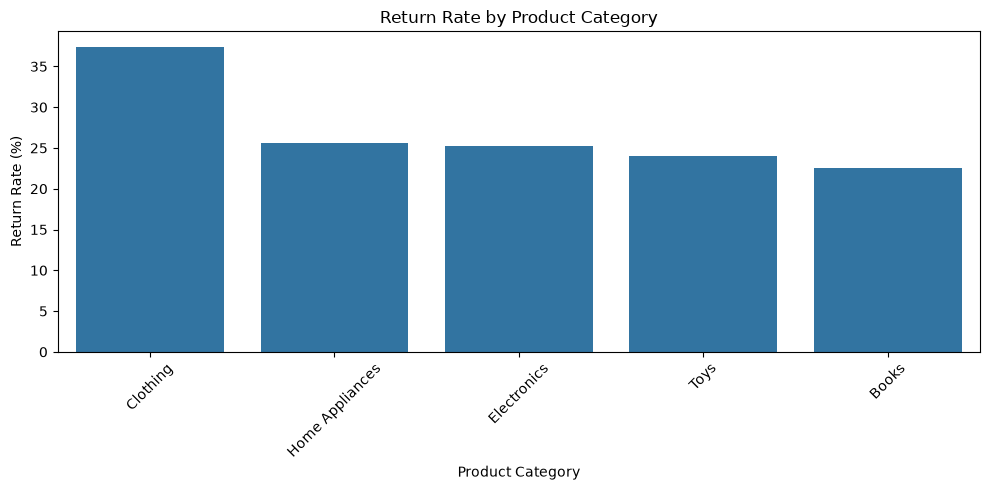

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_analysis,
    x="product_category",
    y="return_rate_pct"
)

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Analyse return reasons

In [16]:
returned_data = df_clean[df_clean["is_returned"]]

reason_analysis = (
    returned_data["return_reason"]
    .fillna("Not recorded")
    .value_counts()
    .reset_index()
)

reason_analysis.columns = ["return_reason", "count"]

display(reason_analysis)

,return_reason,count
0,Defective,382
1,Changed Mind,379
2,Wrong Item,348
3,Size Issue,341


### Visualize return reasons

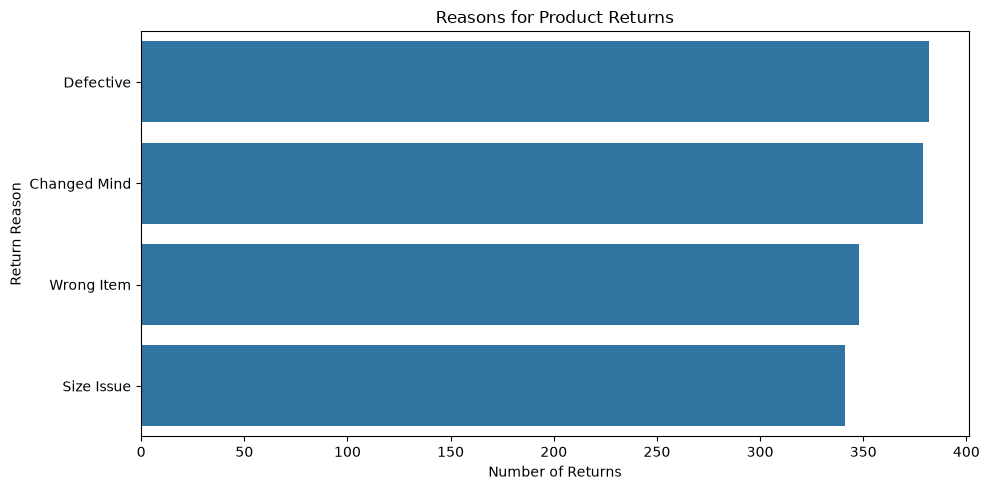

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=reason_analysis,
    x="count",
    y="return_reason"
)

plt.title("Reasons for Product Returns")
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.show()

### Analyse return cost

In [19]:
if "return_cost" in df_clean.columns:
    cost_analysis = (
        returned_data.groupby("product_category")
        .agg(
            total_return_cost=("return_cost", "sum"),
            average_return_cost=("return_cost", "mean")
        )
        .reset_index()
        .sort_values("total_return_cost", ascending=False)
    )

    display(cost_analysis)
else:
    print("Return cost column is not available.")

,product_category,total_return_cost,average_return_cost
1,Clothing,132200,200.0
2,Electronics,62800,200.0
4,Toys,36200,200.0
0,Books,34400,200.0
3,Home Appliances,24400,200.0


### Analyse returns by shipping method

In [20]:
if "shipping_method" in df_clean.columns:
    shipping_analysis = (
        df_clean.groupby("shipping_method")
        .agg(
            total_orders=("is_returned", "size"),
            returned_orders=("is_returned", "sum")
        )
        .reset_index()
    )

    shipping_analysis["return_rate_pct"] = (
        shipping_analysis["returned_orders"]
        / shipping_analysis["total_orders"] * 100
    )

    display(shipping_analysis)
else:
    print("Shipping method column is not available.")

,shipping_method,total_orders,returned_orders,return_rate_pct
0,Express,1633,475,29.087569
1,Next-Day,1684,480,28.503563
2,Standard,1683,495,29.411765


### Analyse monthly return trends

In [21]:
if "order_date" in df_clean.columns:
    df_clean["order_date"] = pd.to_datetime(
        df_clean["order_date"], errors="coerce"
    )

    df_clean["order_month"] = (
        df_clean["order_date"].dt.to_period("M").astype(str)
    )

    monthly_analysis = (
        df_clean.dropna(subset=["order_date"])
        .groupby("order_month")
        .agg(
            total_orders=("is_returned", "size"),
            returned_orders=("is_returned", "sum")
        )
        .reset_index()
    )

    monthly_analysis["return_rate_pct"] = (
        monthly_analysis["returned_orders"]
        / monthly_analysis["total_orders"] * 100
    )

    display(monthly_analysis)
else:
    print("Order date column is not available.")

,order_month,total_orders,returned_orders,return_rate_pct
0,2022-01,132,36,27.272727
1,2022-02,111,32,28.828829
2,2022-03,102,22,21.568627
3,2022-04,118,34,28.813559
4,2022-05,121,31,25.619835
5,2022-06,124,29,23.387097
6,2022-07,121,36,29.752066
7,2022-08,98,28,28.571429
8,2022-09,110,29,26.363636
9,2022-10,103,28,27.184466


### Visualize monthly trends

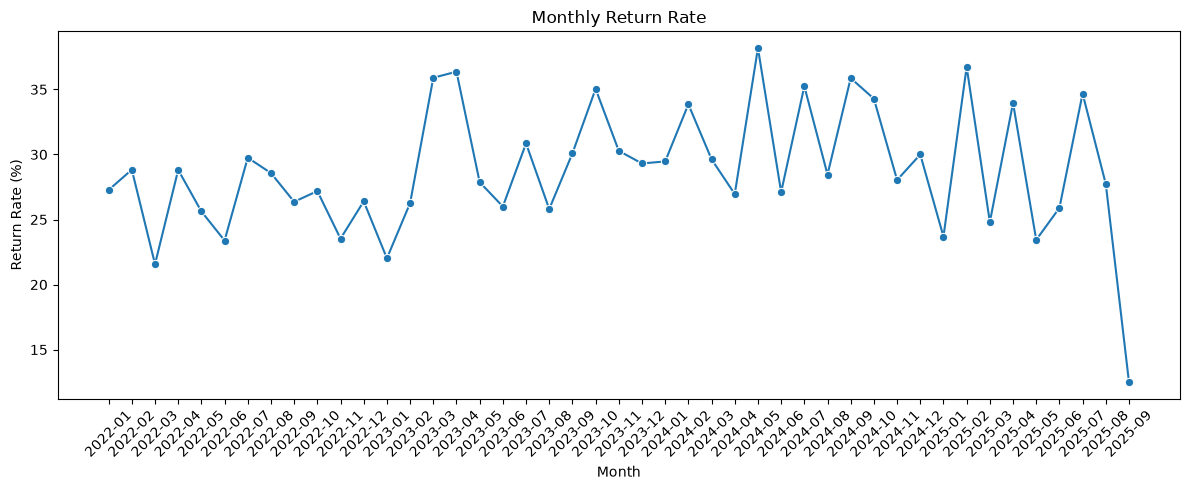

In [22]:
if "monthly_analysis" in globals():
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=monthly_analysis,
        x="order_month",
        y="return_rate_pct",
        marker="o"
    )

    plt.title("Monthly Return Rate")
    plt.xlabel("Month")
    plt.ylabel("Return Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Compare return rates by discount

In [23]:
if "discount_bin" in df_clean.columns:
    discount_analysis = (
        df_clean.groupby("discount_bin")
        .agg(
            total_orders=("is_returned", "size"),
            returned_orders=("is_returned", "sum")
        )
        .reset_index()
    )

    discount_analysis["return_rate_pct"] = (
        discount_analysis["returned_orders"]
        / discount_analysis["total_orders"] * 100
    )

    display(discount_analysis)
else:
    print("Discount column is not available.")

,discount_bin,total_orders,returned_orders,return_rate_pct
0,"(-0.001, 12.828]",1250,319,25.520000
1,"(12.828, 25.02]",1250,317,25.360000
2,"(25.02, 37.38]",1251,408,32.613909
3,"(37.38, 50.0]",1249,406,32.506005


In [24]:
import os

os.makedirs("project_outputs", exist_ok=True)

category_analysis.to_csv(
    "project_outputs/category_analysis.csv",
    index=False
)

reason_analysis.to_csv(
    "project_outputs/reason_analysis.csv",
    index=False
)

df_clean.to_csv(
    "project_outputs/cleaned_data.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!
